In [1]:

# If required, uncomment the following line:
# %pip install pandas numpy matplotlib seaborn scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RANDOM_STATE = 42

print("Libraries imported successfully.")


Libraries imported successfully.


In [4]:

df = pd.read_csv("C:/Users/Victus/Downloads/bank_dataset.csv")

print("Dataset loaded successfully.")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

display(df.head())


Dataset loaded successfully.
Number of rows: 11,162
Number of columns: 17
Memory usage: 6.36 MB


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [5]:

print("DATASET INFORMATION")
df.info()

print("\nMISSING VALUES")
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})
display(missing_summary.sort_values("Missing_Count", ascending=False))

print("\nDUPLICATE ROWS")
print("Duplicate rows:", df.duplicated().sum())

print("\nUNIQUE VALUES PER COLUMN")
display(df.nunique().sort_values(ascending=False).to_frame("Unique_Count"))

print("\nTARGET DISTRIBUTION")
display(df["deposit"].value_counts().to_frame("Count"))
display(
    (df["deposit"].value_counts(normalize=True) * 100)
    .round(2).to_frame("Percentage")
)


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB

MISSING VALUES


,Missing_Count,Missing_Percentage
age,0,0.00
day,0,0.00
poutcome,0,0.00
previous,0,0.00
pdays,0,0.00
campaign,0,0.00
duration,0,0.00
month,0,0.00
contact,0,0.00
job,0,0.00



DUPLICATE ROWS
Duplicate rows: 0

UNIQUE VALUES PER COLUMN


,Unique_Count
balance,3805
duration,1428
pdays,472
age,76
campaign,36
previous,34
day,31
job,12
month,12
poutcome,4



TARGET DISTRIBUTION


,Count
deposit,
no,5873
yes,5289


,Percentage
deposit,
no,52.62
yes,47.38


In [6]:

numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("NUMERICAL DESCRIPTIVE STATISTICS")
display(df[numeric_columns].describe().T)

print("\nCATEGORICAL DESCRIPTIVE STATISTICS")
display(df[categorical_columns].describe().T)

print("\nVALUE COUNTS FOR CATEGORICAL VARIABLES")

for col in categorical_columns:
    print(f"\n{col.upper()}")
    display(df[col].value_counts(dropna=False).to_frame("Count"))


NUMERICAL DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
age,"11,162.00",41.23,11.91,18.00,32.00,39.00,49.00,95.00
balance,"11,162.00","1,528.54","3,225.41","-6,847.00",122.00,550.00,"1,708.00","81,204.00"
day,"11,162.00",15.66,8.42,1.00,8.00,15.00,22.00,31.00
duration,"11,162.00",371.99,347.13,2.00,138.00,255.00,496.00,"3,881.00"
campaign,"11,162.00",2.51,2.72,1.00,1.00,2.00,3.00,63.00
pdays,"11,162.00",51.33,108.76,-1.00,-1.00,-1.00,20.75,854.00
previous,"11,162.00",0.83,2.29,0.00,0.00,0.00,1.00,58.00



CATEGORICAL DESCRIPTIVE STATISTICS


,count,unique,top,freq
job,11162,12,management,2566
marital,11162,3,married,6351
education,11162,4,secondary,5476
default,11162,2,no,10994
housing,11162,2,no,5881
loan,11162,2,no,9702
contact,11162,3,cellular,8042
month,11162,12,may,2824
poutcome,11162,4,unknown,8326
deposit,11162,2,no,5873



VALUE COUNTS FOR CATEGORICAL VARIABLES

JOB


...

,Count
month,
may,2824
aug,1519
jul,1514
jun,1222
nov,943
apr,923
feb,776
oct,392
jan,344



POUTCOME


,Count
poutcome,
unknown,8326
failure,1228
success,1071
other,537



DEPOSIT


,Count
deposit,
no,5873
yes,5289


In [7]:

df_clean = df.copy()

# Remove exact duplicate records
duplicates_before = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().copy()

# Standardize column names
df_clean.columns = df_clean.columns.str.strip().str.lower()

# Remove accidental whitespace from categorical values
for col in df_clean.select_dtypes(include=["object", "category"]).columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()

# Verify target labels
print("Target labels:", df_clean["deposit"].unique())

# Check missing values after cleaning
print("\nMissing values after cleaning:")
display(df_clean.isnull().sum().to_frame("Missing_Count"))

print(f"\nDuplicates removed: {duplicates_before}")
print(f"Rows after cleaning: {len(df_clean):,}")


Target labels: <StringArray>
['yes', 'no']
Length: 2, dtype: string

Missing values after cleaning:


,Missing_Count
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0



Duplicates removed: 0
Rows after cleaning: 11,162


In [8]:

outlier_results = []

for col in numeric_columns:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ).sum()

    outlier_results.append({
        "Variable": col,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outlier_count,
        "Outlier_Percentage": 100 * outlier_count / len(df_clean)
    })

outlier_df = pd.DataFrame(outlier_results)
display(outlier_df.sort_values("Outlier_Percentage", ascending=False))


,Variable,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
5,pdays,-33.62,53.38,2750,24.64
6,previous,-1.50,2.50,1258,11.27
1,balance,"-2,257.00","4,087.00",1055,9.45
3,duration,-399.00,"1,033.00",636,5.70
4,campaign,-2.00,6.00,601,5.38
0,age,6.50,74.50,171,1.53
2,day,-13.00,43.00,0,0.00


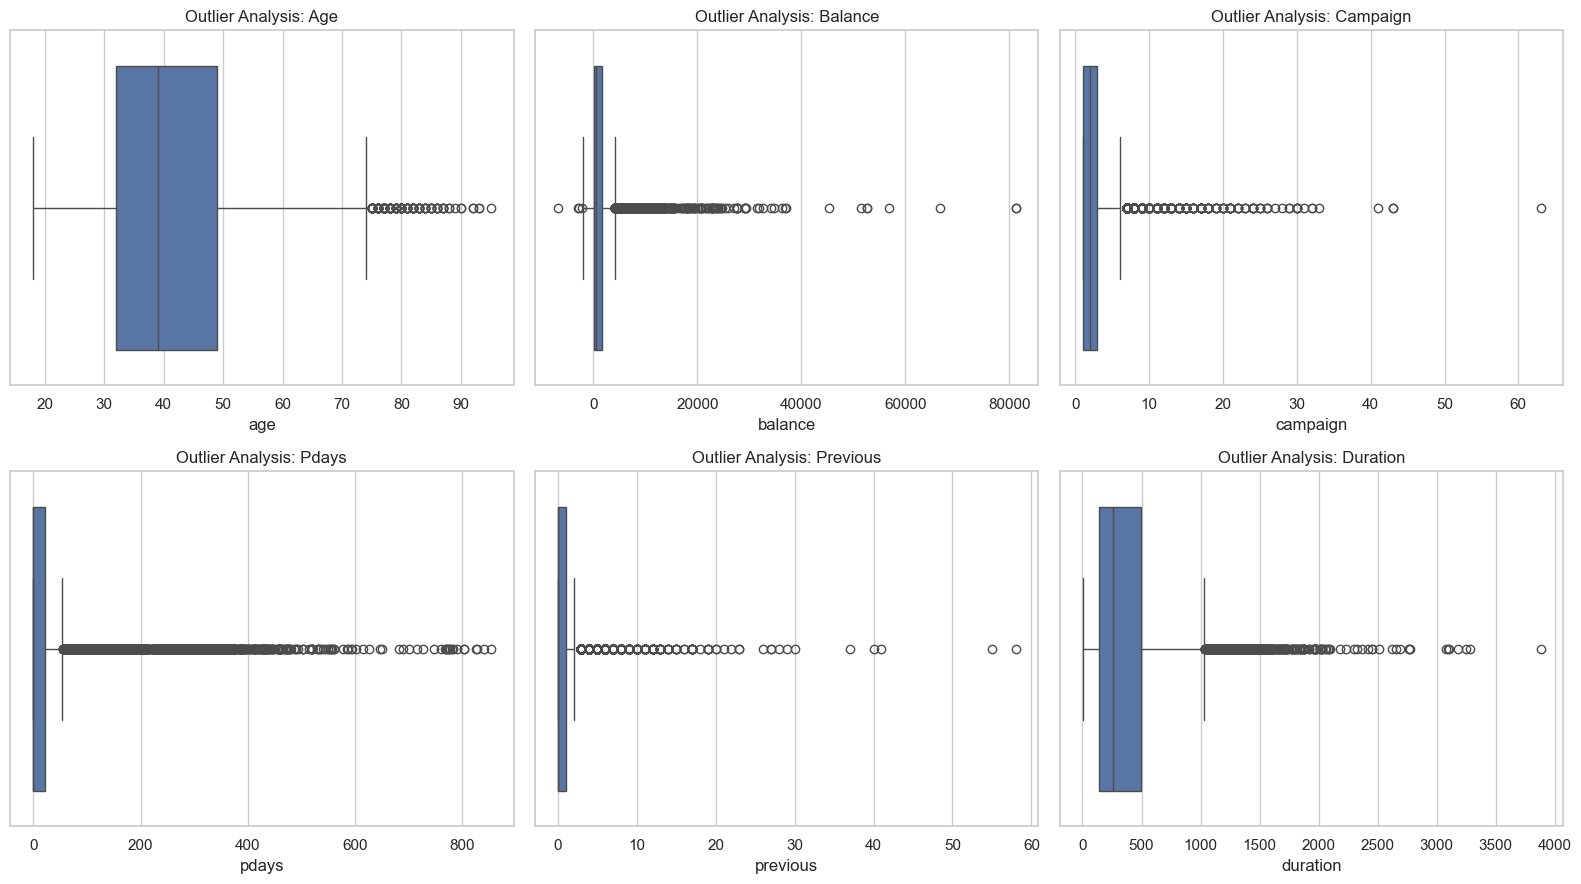

In [9]:

plot_columns = ["age", "balance", "campaign", "pdays", "previous", "duration"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flatten(), plot_columns):
    sns.boxplot(data=df_clean, x=col, ax=ax)
    ax.set_title(f"Outlier Analysis: {col.capitalize()}")

plt.tight_layout()
plt.show()


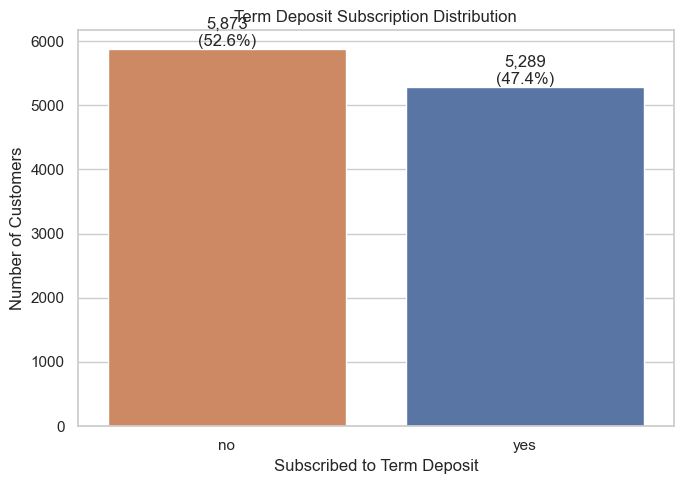

In [10]:

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df_clean,
    x="deposit",
    hue="deposit",
    order=["no", "yes"],
    legend=False
)

ax.set_title("Term Deposit Subscription Distribution")
ax.set_xlabel("Subscribed to Term Deposit")
ax.set_ylabel("Number of Customers")

total = len(df_clean)

for bar in ax.patches:
    count = int(bar.get_height())
    ax.annotate(
        f"{count:,}\n({count / total:.1%})",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


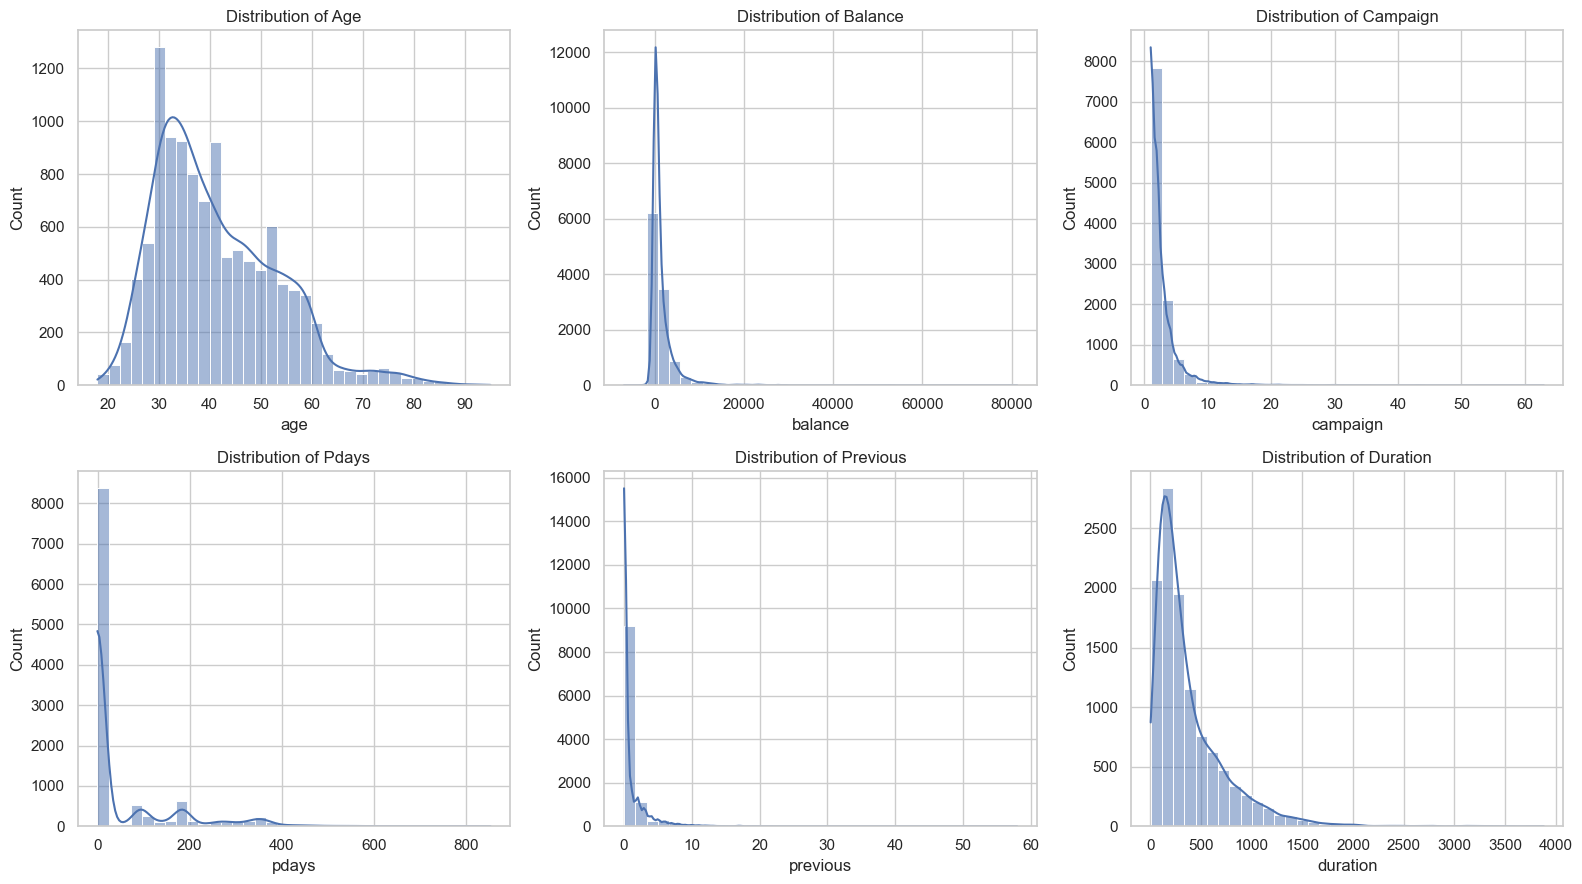

In [11]:

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flatten(), plot_columns):
    sns.histplot(
        data=df_clean,
        x=col,
        bins=35,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {col.capitalize()}")

plt.tight_layout()
plt.show()


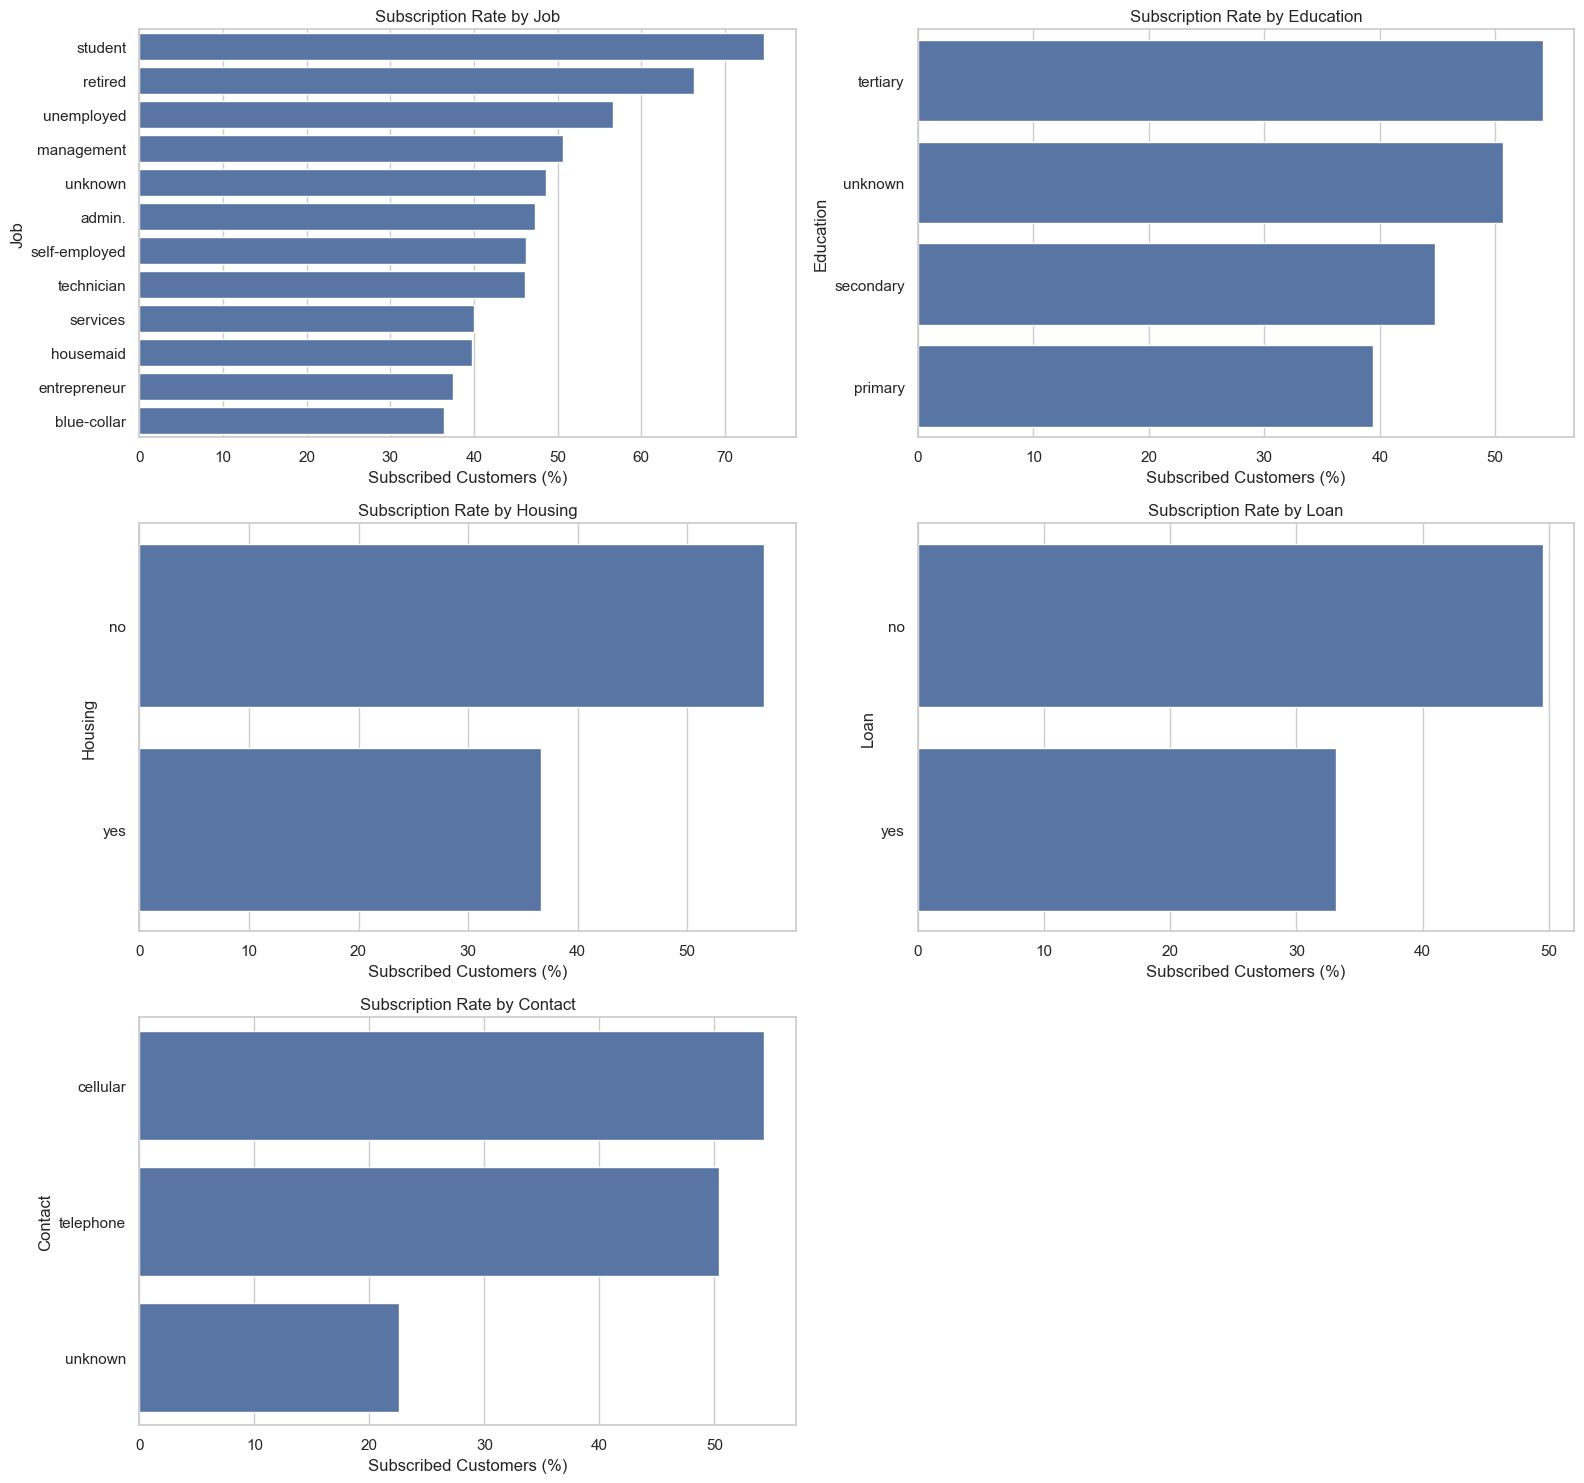

In [12]:

category_plots = ["job", "education", "housing", "loan", "contact"]

fig, axes = plt.subplots(3, 2, figsize=(16, 15))
axes = axes.flatten()

for ax, col in zip(axes, category_plots):
    rates = (
        df_clean.groupby(col, observed=True)["deposit"]
        .apply(lambda s: (s == "yes").mean() * 100)
        .sort_values(ascending=False)
        .reset_index(name="Subscription_Rate")
    )

    sns.barplot(
        data=rates,
        x="Subscription_Rate",
        y=col,
        ax=ax
    )

    ax.set_title(f"Subscription Rate by {col.capitalize()}")
    ax.set_xlabel("Subscribed Customers (%)")
    ax.set_ylabel(col.capitalize())

axes[-1].axis("off")
plt.tight_layout()
plt.show()


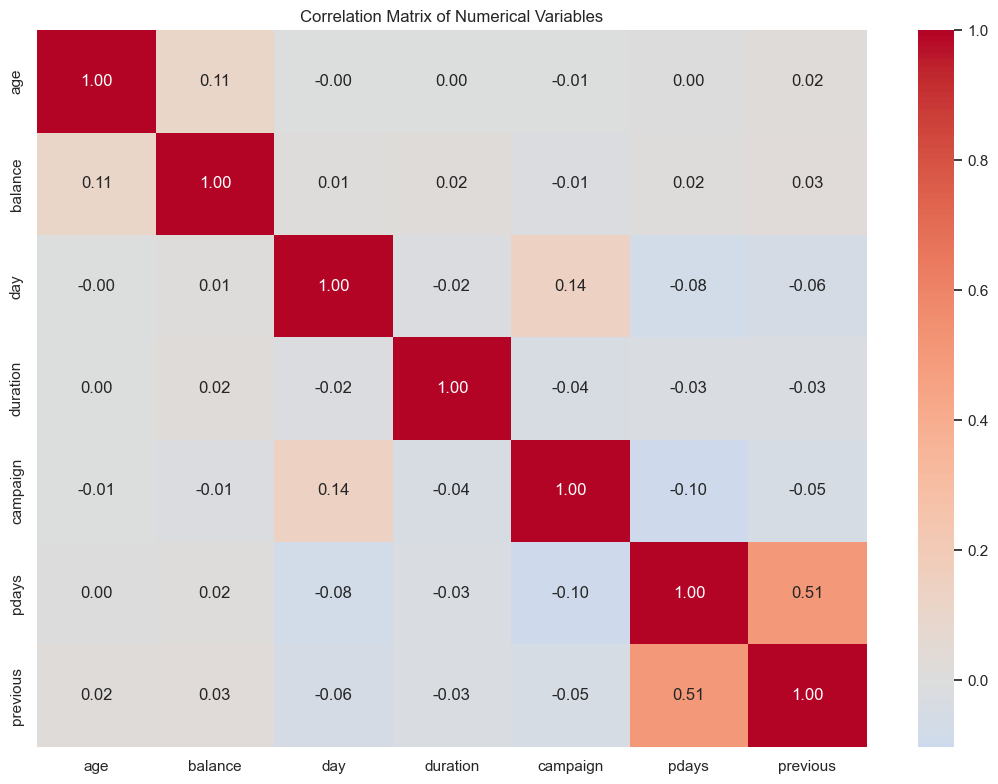

In [13]:

plt.figure(figsize=(11, 8))

correlation_matrix = df_clean[numeric_columns].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()


In [14]:

# Create the target variable
y = df_clean["deposit"].map({"no": 0, "yes": 1})

# Copy the original features, excluding target and post-call duration
X = df_clean.drop(columns=["deposit", "duration", "pdays"]).copy()

# Represent whether the customer was contacted previously
X["previously_contacted"] = (
    df_clean["pdays"] != -1
).astype(int)

# Identify numerical and categorical predictors
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)
print("\nTotal predictors:", X.shape[1])

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTraining observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).rename("Proportion"))

print("\nTesting target proportions:")
display(y_test.value_counts(normalize=True).rename("Proportion"))


Numerical features: ['age', 'balance', 'day', 'campaign', 'previous', 'previously_contacted']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Total predictors: 15

Training observations: 8929
Testing observations: 2233

Training target proportions:


deposit
0   0.53
1   0.47
Name: Proportion, dtype: float64


Testing target proportions:


deposit
0   0.53
1   0.47
Name: Proportion, dtype: float64

In [15]:

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combined preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

# Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# Train both models
logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("Both models have been trained successfully.")


Both models have been trained successfully.


In [16]:

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

results = []

for model_name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1_Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))


,Accuracy,Precision,Recall,F1_Score,ROC_AUC
Model,,,,,
Logistic Regression,0.69,0.71,0.59,0.65,0.76
Random Forest,0.74,0.77,0.64,0.70,0.79


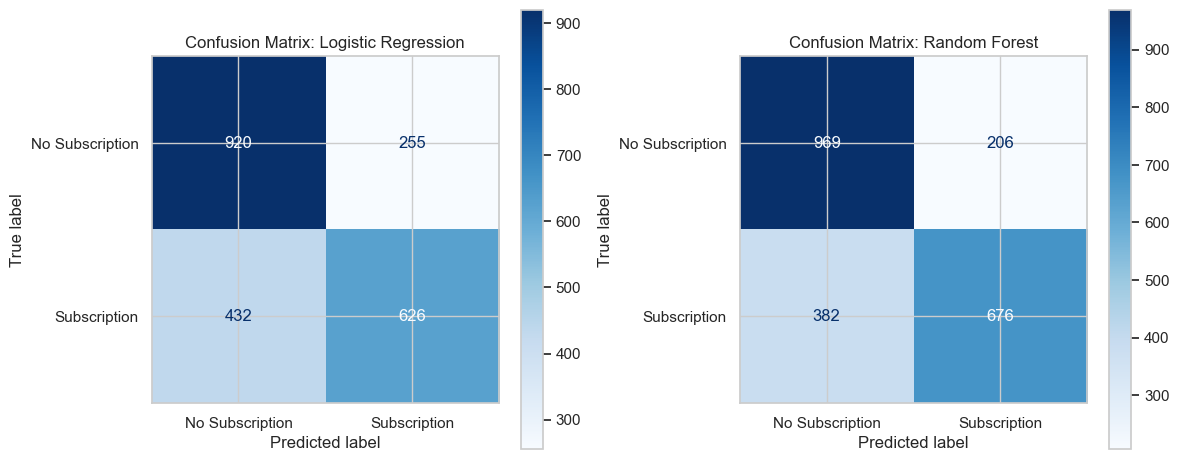

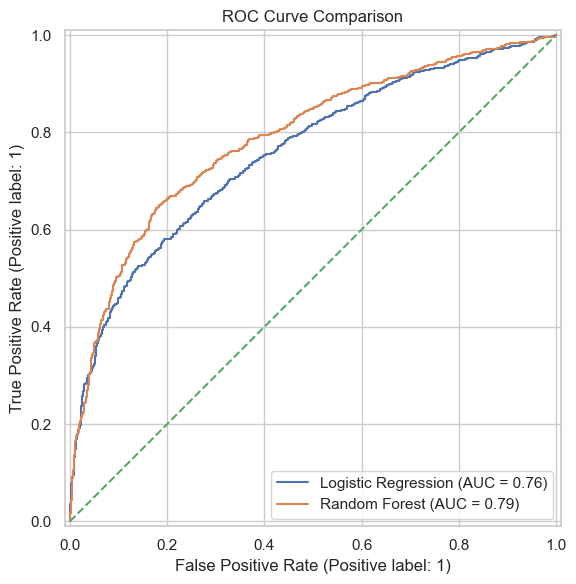

In [17]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (model_name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=["No Subscription", "Subscription"],
        cmap="Blues",
        ax=ax
    )
    ax.set_title(f"Confusion Matrix: {model_name}")

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))

for model_name, model in models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=model_name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set_title("ROC Curve Comparison")
plt.tight_layout()
plt.show()


In [18]:

for model_name, model in models.items():
    print(f"\n{'=' * 60}")
    print(model_name.upper())
    print("=" * 60)

    y_pred = model.predict(X_test)

    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["No Subscription", "Subscription"],
        zero_division=0
    ))



LOGISTIC REGRESSION
                 precision    recall  f1-score   support

No Subscription       0.68      0.78      0.73      1175
   Subscription       0.71      0.59      0.65      1058

       accuracy                           0.69      2233
      macro avg       0.70      0.69      0.69      2233
   weighted avg       0.69      0.69      0.69      2233


RANDOM FOREST
                 precision    recall  f1-score   support

No Subscription       0.72      0.82      0.77      1175
   Subscription       0.77      0.64      0.70      1058

       accuracy                           0.74      2233
      macro avg       0.74      0.73      0.73      2233
   weighted avg       0.74      0.74      0.73      2233



In [19]:

fitted_preprocessor = logistic_model.named_steps["preprocessor"]
fitted_classifier = logistic_model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = fitted_classifier.coef_[0]

coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Odds_Ratio": np.exp(np.clip(coefficients, -20, 20))
})

coefficient_df["Absolute_Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

print("Top 15 positive associations:")
display(
    coefficient_df.sort_values("Coefficient", ascending=False)
    .head(15)[["Feature", "Coefficient", "Odds_Ratio"]]
)

print("\nTop 15 negative associations:")
display(
    coefficient_df.sort_values("Coefficient", ascending=True)
    .head(15)[["Feature", "Coefficient", "Odds_Ratio"]]
)


Top 15 positive associations:


,Feature,Coefficient,Odds_Ratio
48,cat__poutcome_success,1.35,3.88
41,cat__month_mar,1.31,3.69
36,cat__month_dec,1.23,3.41
44,cat__month_oct,0.71,2.03
14,cat__job_student,0.66,1.94
45,cat__month_sep,0.64,1.90
31,cat__contact_cellular,0.51,1.66
11,cat__job_retired,0.43,1.54
5,num__previously_contacted,0.27,1.31
29,cat__loan_no,0.21,1.24



Top 15 negative associations:


,Feature,Coefficient,Odds_Ratio
38,cat__month_jan,-1.00,0.37
43,cat__month_nov,-0.81,0.44
46,cat__poutcome_failure,-0.77,0.46
35,cat__month_aug,-0.74,0.48
33,cat__contact_unknown,-0.71,0.49
39,cat__month_jul,-0.59,0.55
47,cat__poutcome_other,-0.49,0.61
37,cat__month_feb,-0.49,0.61
42,cat__month_may,-0.44,0.64
17,cat__job_unknown,-0.40,0.67


,Feature,Importance
1,num__balance,0.13
0,num__age,0.11
2,num__day,0.10
48,cat__poutcome_success,0.06
3,num__campaign,0.05
33,cat__contact_unknown,0.05
4,num__previous,0.03
31,cat__contact_cellular,0.03
28,cat__housing_yes,0.03
27,cat__housing_no,0.03


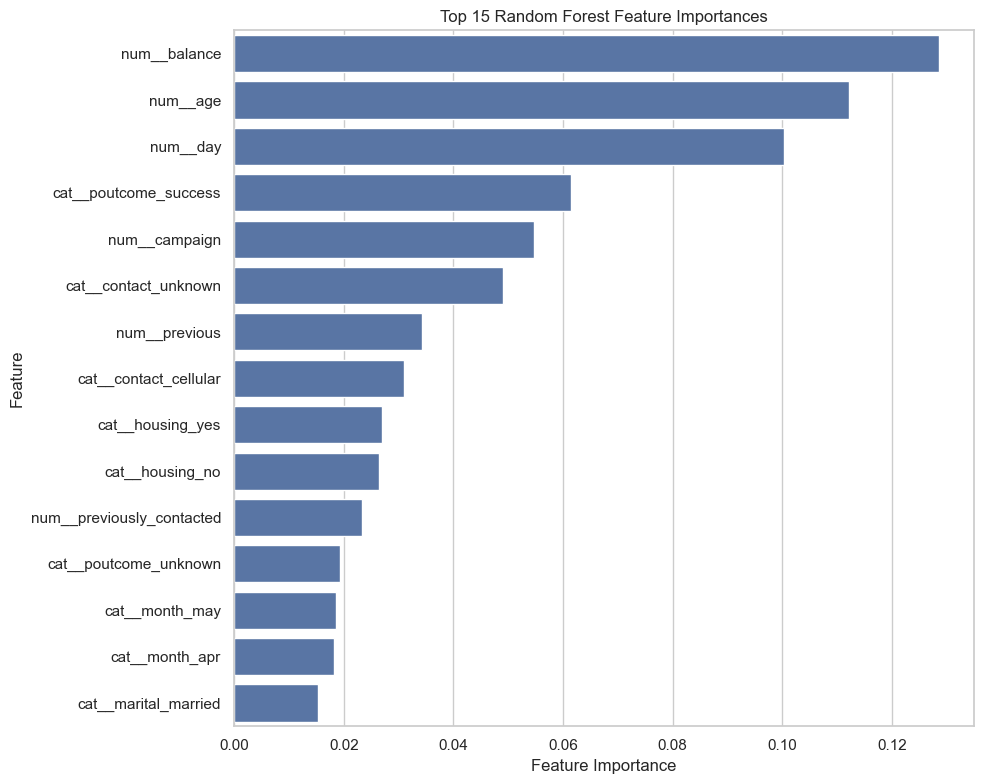

In [20]:

rf_preprocessor = random_forest_model.named_steps["preprocessor"]
rf_classifier = random_forest_model.named_steps["classifier"]

rf_feature_names = rf_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_classifier.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.head(20))

plt.figure(figsize=(10, 8))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


In [21]:

analysis_df = df_clean.copy()
analysis_df["subscribed"] = (
    analysis_df["deposit"] == "yes"
).astype(int)

overall_rate = analysis_df["subscribed"].mean() * 100

print(f"Overall subscription rate: {overall_rate:.2f}%")

# Analyze subscription rates by selected customer attributes
for col in ["job", "education", "housing", "loan", "contact", "poutcome"]:
    summary = (
        analysis_df.groupby(col, observed=True)
        .agg(
            Customers=("subscribed", "size"),
            Subscriptions=("subscribed", "sum"),
            Subscription_Rate=("subscribed", "mean")
        )
        .sort_values("Subscription_Rate", ascending=False)
    )

    summary["Subscription_Rate"] *= 100

    print(f"\nSUBSCRIPTION ANALYSIS: {col.upper()}")
    display(summary.round(2))

# Campaign contact frequency
campaign_summary = (
    analysis_df.groupby("campaign")
    .agg(
        Customers=("subscribed", "size"),
        Subscription_Rate=("subscribed", "mean")
    )
)

campaign_summary["Subscription_Rate"] *= 100

print("\nCAMPAIGN CONTACT FREQUENCY")
display(campaign_summary.head(15).round(2))

# Overall summary
print("\nDATASET SUMMARY")
print(f"Total customers: {len(analysis_df):,}")
print(f"Customers who subscribed: {analysis_df['subscribed'].sum():,}")
print(f"Customers who did not subscribe: {(1 - analysis_df['subscribed']).sum():,}")


Overall subscription rate: 47.38%

SUBSCRIPTION ANALYSIS: JOB


,Customers,Subscriptions,Subscription_Rate
job,,,
student,360,269,74.72
retired,778,516,66.32
unemployed,357,202,56.58
management,2566,1301,50.70
unknown,70,34,48.57
admin.,1334,631,47.30
self-employed,405,187,46.17
technician,1823,840,46.08
services,923,369,39.98



SUBSCRIPTION ANALYSIS: EDUCATION


,Customers,Subscriptions,Subscription_Rate
education,,,
tertiary,3689,1996,54.11
unknown,497,252,50.70
secondary,5476,2450,44.74
primary,1500,591,39.40



SUBSCRIPTION ANALYSIS: HOUSING


...


SUBSCRIPTION ANALYSIS: POUTCOME


,Customers,Subscriptions,Subscription_Rate
poutcome,,,
success,1071,978,91.32
other,537,307,57.17
failure,1228,618,50.33
unknown,8326,3386,40.67



CAMPAIGN CONTACT FREQUENCY


,Customers,Subscription_Rate
campaign,,
1,4798,53.38
2,3028,46.27
3,1321,46.78
4,771,41.12
5,378,36.77
6,265,34.72
7,139,33.81
8,128,25.00
9,72,29.17



DATASET SUMMARY
Total customers: 11,162
Customers who subscribed: 5,289
Customers who did not subscribe: 5,873
